# Deposit forecasting: results walk-through

Forecasting German household overnight deposits (ECB data) with six models, judged on
accuracy, transparency and effort. The notebook calls the package functions and reads the
committed backtest tables in `results/`; regenerate them with
`uv run deposit-forecasting-backtest --out results`.

In [1]:
%matplotlib inline
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from deposit_forecasting.data import load_panel
from deposit_forecasting.figures import (
    DEFAULT_FIGURE_DIR, LABELS, load_results, plot_coverage_by_horizon,
    plot_mae_by_horizon, plot_turn_forecasts, summary_table,
)
from deposit_forecasting.models import TARGET

warnings.filterwarnings("ignore")
panel = load_panel()
scores, forecasts = load_results()
print(f"Panel: {panel.index[0]} to {panel.index[-1]} ({len(panel)} months); "
      f"status of the last deposits value: {panel.attrs['last_deposit_status']} (provisional)")

Panel: 2003-01 to 2026-09 (285 months); status of the last deposits value: P (provisional)


## 1. Data and rates

The target is the end-of-month stock of overnight deposits of households and NPISH at German
MFIs (EUR bn, not seasonally adjusted). Drivers are the bank rates on overnight and short
time deposits and the ECB deposit facility rate. The spread (time deposit rate minus overnight
rate) is the opportunity cost of holding money at call.

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
x = panel.index.to_timestamp()
axes[0].plot(x, panel[TARGET], color="black")
axes[0].set_ylabel("Deposits (EUR bn)")
axes[1].plot(x, panel["deposit_facility_rate"], label="ECB deposit facility rate", color="#7f7f7f")
axes[1].plot(x, panel["overnight_rate"], label="Overnight deposit rate", color="#1f77b4")
axes[1].plot(x, panel["time_deposit_rate"], label="Time deposit rate (up to 1 year)", color="#d95f02")
axes[1].set_ylabel("Rate (% p.a.)")
axes[1].legend(fontsize=8)
axes[2].plot(x, panel["spread"], color="#d95f02")
axes[2].set_ylabel("Spread (pp)")
axes[2].set_xlabel("Month")
axes[0].axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2023-12-31"), color="gray", alpha=0.15)
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].set_title("Deposits and rates (shaded: 2022-2023 rate turn)")
fig.text(0.01, 0.005, "Source: ECB Data Portal; own calculations", fontsize=8, color="dimgray")
plt.show()

## 2. Planned outflows on a synthetic book

Public data is aggregate, so announced departures of large clients cannot be shown on the ECB
series. The demo below uses a **fictional, synthetic** bank: a retail trend plus a few large
clients that leave on announced dates. It illustrates the logic only and says nothing about real
accuracy.

In [3]:
from deposit_forecasting.synthetic import demonstrate, generate_synthetic_book

book = generate_synthetic_book()
demo = demonstrate(book)
print(book.label)
display(book.departures)
ax = demo.plot(figsize=(9, 4), color=["black", "#7f7f7f", "#d95f02"], grid=True)
ax.set_title("SYNTHETIC deposit book: drift forecast with and without planned outflows")
ax.set_ylabel("Deposits (EUR bn, synthetic)")
plt.show()
print((demo[["drift", "drift_with_outflows"]].sub(demo["realised"], axis=0).abs().mean()
       .rename("MAE (EUR bn, synthetic)")).round(3))

SYNTHETIC DATA (fictional bank, not real deposits)


,balance,departure_month
Synthetic Client 01,0.446,2023-02
Synthetic Client 02,0.211,2023-04
Synthetic Client 03,0.488,2023-05
Synthetic Client 04,0.206,2023-09
Synthetic Client 05,0.503,2023-11


drift                  1.094
drift_with_outflows    0.049
Name: MAE (EUR bn, synthetic), dtype: float64


## 3. Models and backtest

Six models share one `fit`/`predict` interface: naive, drift, ETS, SARIMA, a rate regression
and LightGBM. Each is refitted at every monthly origin from 2010-12 (expanding window) and
forecasts 1 to 12 months ahead. Driver models receive the realised rates of the forecast months
(ex-post conditional evaluation). Scores are shown for all target months and for the
2022-2023 rate turn.

MAE is in EUR bn, coverage is the share of actuals inside the nominal 80 % band.

In [4]:
table = summary_table(scores)
print("MAE (EUR bn) and band coverage (%) by model and horizon")
display(table.round(1))

MAE (EUR bn) and band coverage (%) by model and horizon


segment             full                                          rate_turn  \
                coverage                    mae                    coverage   
horizon               1     3     6     12   1     3     6     12        1    
Model                                                                         
Naive               55.6  23.5  10.3   3.9  9.6  25.1  50.3  99.0      54.2   
Drift               75.7  71.7  58.7  55.1  7.8  15.5  28.0  54.5      66.7   
ETS                 93.1  92.0  90.8  92.1  5.7  10.8  22.6  48.3      87.5   
SARIMA              94.2  94.6  93.5  88.8  5.3   9.6  19.4  40.4      79.2   
Rate regression     90.5  85.6  79.9  73.6  6.9  13.7  26.4  50.7      66.7   
LightGBM            76.2  72.2  71.2  61.2  5.8  12.0  21.5  36.6      58.3   

segment                                                     
                                    mae                     
horizon            3     6     12    1     3     6      12  
Model                                                       
Naive            37.5  20.8  16.7   9.7  22.8  42.1   63.2  
Drift            33.3  12.5   0.0  13.1  34.4  70.1  131.5  
ETS              75.0  79.2  79.2   7.7  16.3  34.1   76.6  
SARIMA           75.0  70.8  45.8   8.5  20.8  47.1  129.0  
Rate regression  33.3  12.5   0.0  14.2  37.8  80.1  159.2  
LightGBM         29.2  16.7  12.5   9.5  33.0  68.3   97.1

### Full table with MAPE

In [5]:
full = scores.assign(coverage=100 * scores["coverage"]).round(2)
for segment in ("full", "rate_turn"):
    part = full[full["segment"] == segment]
    wide = part.pivot(index="model", columns="horizon", values=["mae", "mape", "coverage"])
    print(segment)
    display(wide.loc[list(LABELS)].rename(index=LABELS))

full


mae                                                          \
horizon            1      2      3      4      5      6      7      8      9    
model                                                                           
Naive            9.62  16.84  25.07  33.49  41.86  50.31  58.68  66.78  74.92   
Drift            7.84  11.74  15.47  20.39  24.10  28.03  33.24  37.44  42.19   
ETS              5.71   7.99  10.82  14.86  18.51  22.59  27.01  30.88  35.02   
SARIMA           5.34   7.43   9.58  13.43  16.27  19.35  23.27  26.27  29.35   
Rate regression  6.87  10.22  13.66  18.23  22.23  26.36  30.79  34.48  38.83   
LightGBM         5.80   8.92  11.96  15.40  17.66  21.51  26.00  29.09  31.55   

                        ... coverage                                     \
horizon             10  ...       3      4      5      6      7      8    
model                   ...                                               
Naive            83.11  ...    23.53  17.20  12.43  10.33   8.74   7.69   
Drift            46.85  ...    71.66  66.67  65.95  58.70  58.47  54.95   
ETS              39.61  ...    91.98  91.94  90.81  90.76  90.16  90.11   
SARIMA           33.46  ...    94.65  93.55  94.59  93.48  92.90  92.86   
Rate regression  42.77  ...    85.56  83.33  80.54  79.89  76.50  75.27   
LightGBM         33.87  ...    72.19  68.82  70.27  71.20  71.04  69.23   

                                             
horizon             9      10     11     12  
model                                        
Naive             6.08   6.11   3.91   3.93  
Drift            53.04  52.78  53.07  55.06  
ETS              90.06  91.11  91.62  92.13  
SARIMA           92.27  90.56  89.94  88.76  
Rate regression  74.59  74.44  75.42  73.60  
LightGBM         66.30  66.11  62.01  61.24  

[6 rows x 36 columns]

rate_turn


mae                                                    \
horizon             1      2      3      4      5      6      7       8    
model                                                                      
Naive             9.71  15.45  22.80  29.87  36.28  42.13  46.58   50.31   
Drift            13.08  23.03  34.43  46.42  57.99  70.14  81.86   93.52   
ETS               7.66  10.81  16.33  21.88  27.81  34.11  40.55   46.17   
SARIMA            8.54  13.63  20.77  27.88  36.14  47.14  59.52   72.49   
Rate regression  14.16  24.42  37.82  51.32  65.59  80.10  94.33  108.66   
LightGBM          9.49  20.21  33.04  45.54  52.92  68.28  78.61   84.29   

                                 ... coverage                              \
horizon              9       10  ...       3      4      5      6      7    
model                            ...                                        
Naive             53.64   58.09  ...    37.50  25.00  25.00  20.83  20.83   
Drift            104.22  114.36  ...    33.33  29.17  29.17  12.50  12.50   
ETS               53.70   61.12  ...    75.00  83.33  79.17  79.17  75.00   
SARIMA            85.81  100.76  ...    75.00  70.83  66.67  70.83  66.67   
Rate regression  122.13  135.40  ...    33.33  25.00  20.83  12.50   8.33   
LightGBM          91.44   93.29  ...    29.17  25.00  16.67  16.67  16.67   

                                                    
horizon             8      9      10     11     12  
model                                               
Naive            16.67  16.67  25.00  16.67  16.67  
Drift             4.17   0.00   0.00   0.00   0.00  
ETS              75.00  79.17  83.33  79.17  79.17  
SARIMA           66.67  62.50  58.33  50.00  45.83  
Rate regression   0.00   0.00   0.00   0.00   0.00  
LightGBM         20.83   8.33  12.50   8.33  12.50  

[6 rows x 36 columns]

### Error and coverage by horizon

The 2022-2023 target months are a stress test: deposits were flat in 2022 and fell in 2023 while rates rose.

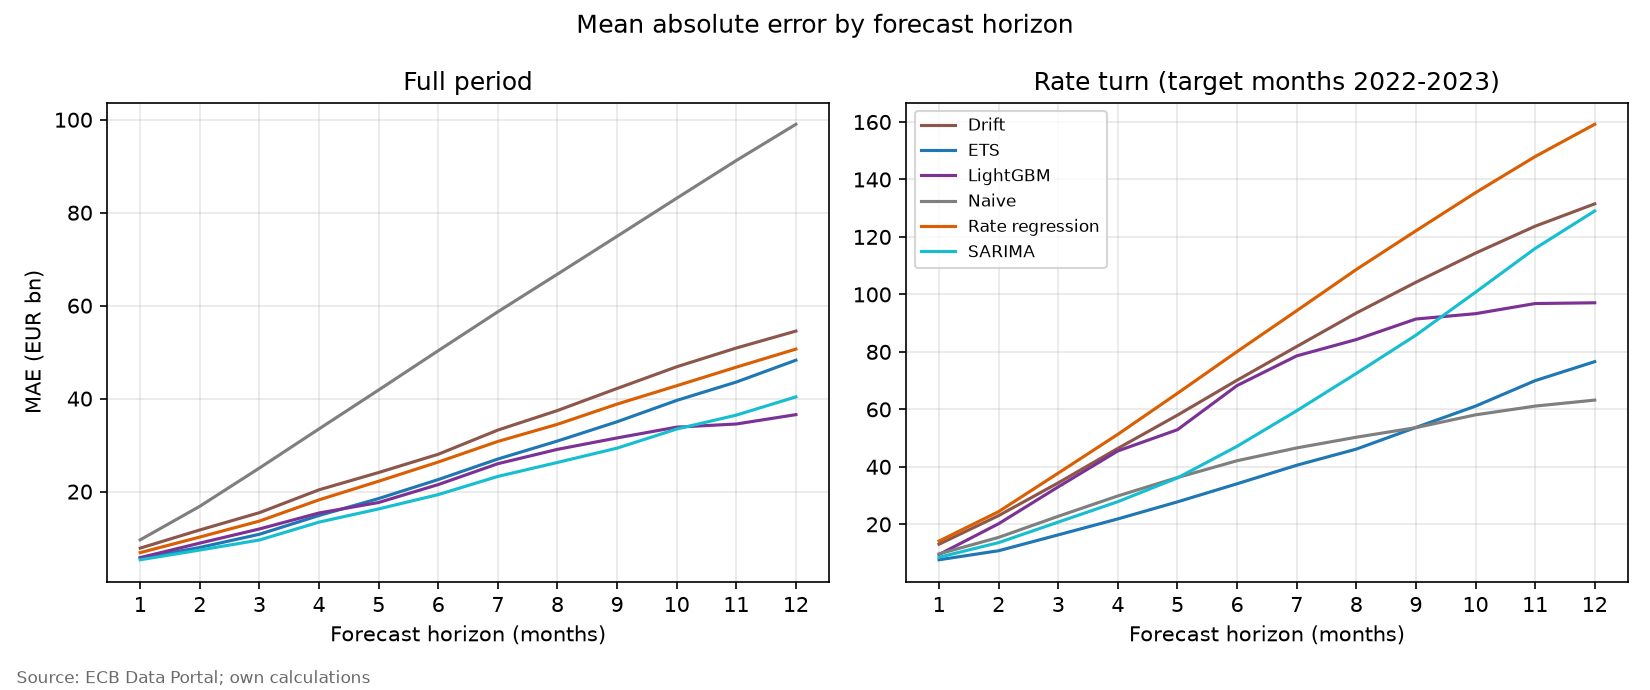

In [6]:
plot_mae_by_horizon(scores, DEFAULT_FIGURE_DIR / "mae_by_horizon.png")
display(Image(DEFAULT_FIGURE_DIR / "mae_by_horizon.png"))

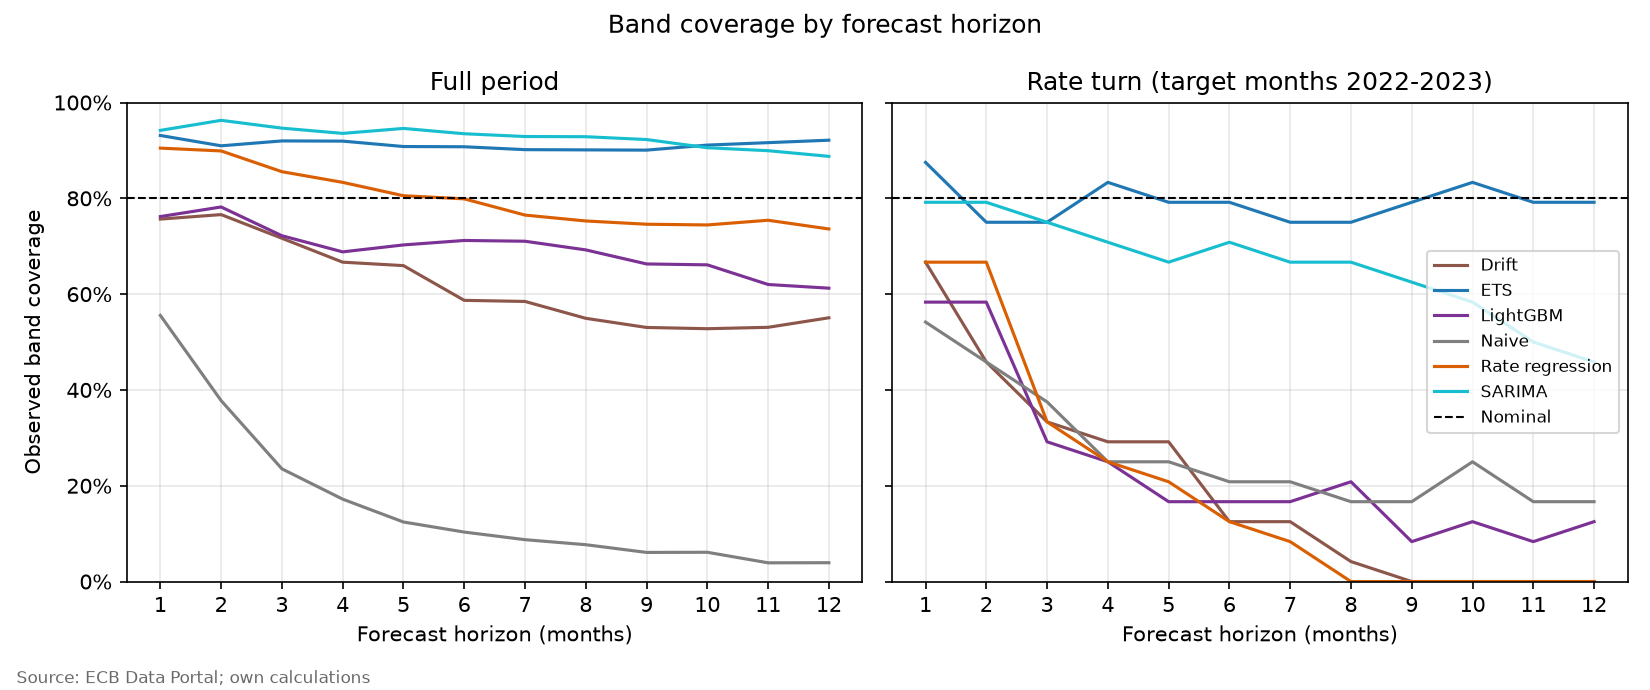

In [7]:
plot_coverage_by_horizon(scores, DEFAULT_FIGURE_DIR / "coverage_by_horizon.png")
display(Image(DEFAULT_FIGURE_DIR / "coverage_by_horizon.png"))

### Forecasts from just before the rate turn

Twelve-month forecasts made at 2021-12 against the realised path. The rate-driven models
extrapolate the effect of rising rates on deposits; deposits instead stayed flat in 2022 and then fell.

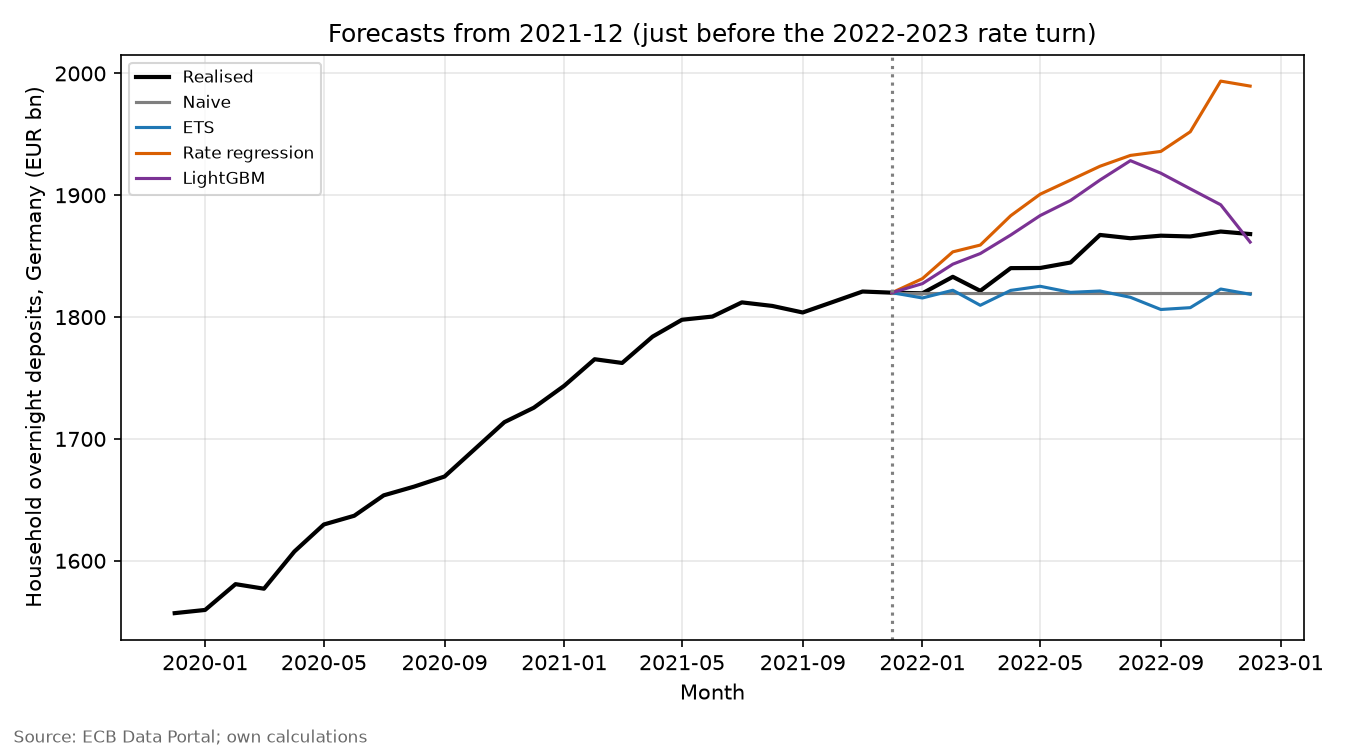

In [8]:
plot_turn_forecasts(forecasts, panel[TARGET], DEFAULT_FIGURE_DIR / "rate_turn_forecasts.png")
display(Image(DEFAULT_FIGURE_DIR / "rate_turn_forecasts.png"))

## 4. Rate scenarios

A parallel shift of the ECB deposit facility rate by +/-100 bp is passed through to the bank
rates with an estimated partial-adjustment regression; the resulting spread path drives the rate
regression. Scenarios are conditional model responses, not forecasts of ECB decisions.

Pass-through of the deposit facility rate to bank rates


,phi,impact,long_run
overnight_rate,0.980,0.012,0.594
time_deposit_rate,0.901,0.090,0.903


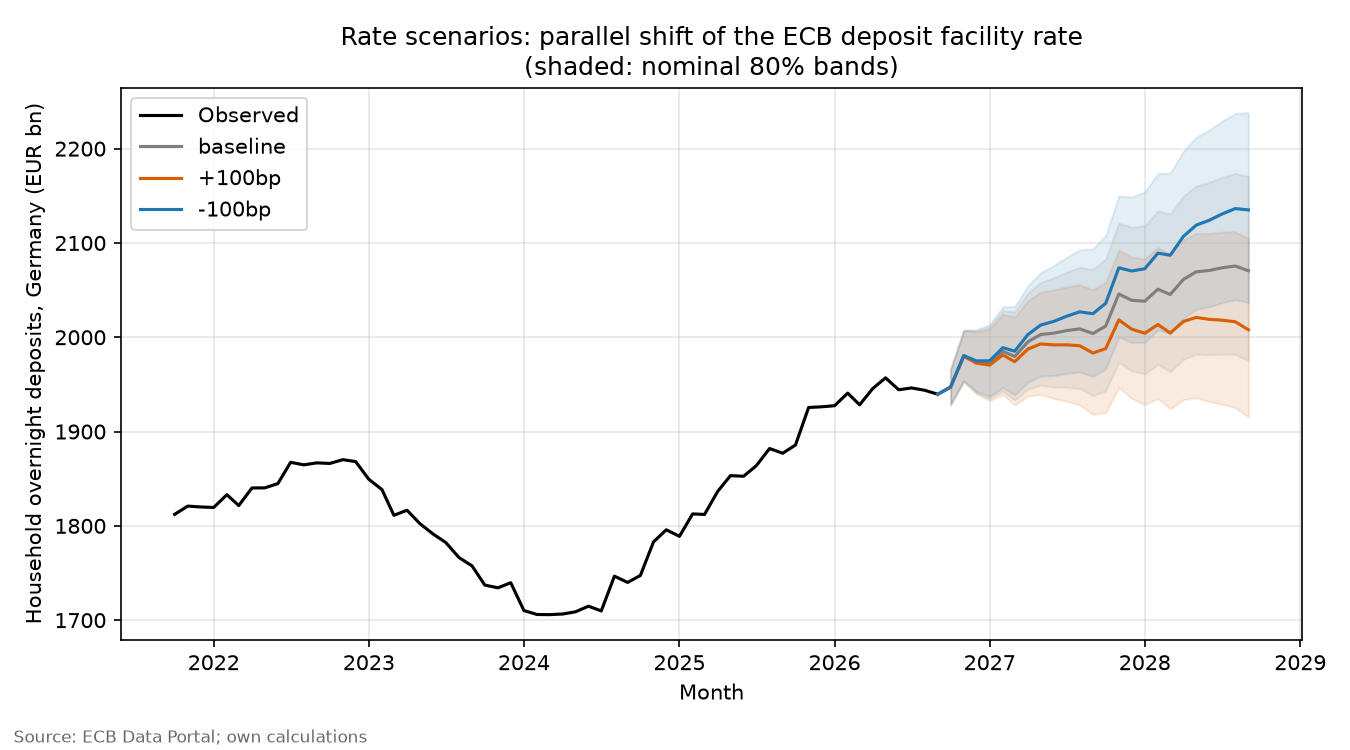

Last scenario month, EUR bn (spread in pp)


,month,mean,lower,upper,spread
scenario,,,,,
baseline,2028-09,2070.5,1975.1,2170.6,1.87
+100bp,2028-09,2007.9,1915.4,2105.0,2.47
-100bp,2028-09,2135.0,2036.6,2238.2,1.27


In [9]:
from deposit_forecasting.scenarios import estimate_pass_through, run_scenarios, plot_scenarios

print("Pass-through of the deposit facility rate to bank rates")
display(estimate_pass_through(panel).round(3))
scenarios = run_scenarios(panel)
plot_scenarios(panel, scenarios, DEFAULT_FIGURE_DIR / "rate_scenarios.png")
display(Image(DEFAULT_FIGURE_DIR / "rate_scenarios.png"))
last = scenarios.groupby("scenario", sort=False).tail(1).set_index("scenario")
print("Last scenario month, EUR bn (spread in pp)")
display(last.assign(month=last["month"].astype(str)).round({"mean": 1, "lower": 1, "upper": 1, "spread": 2}))

## 5. What drives the gradient-boosting model

SHAP values of the LightGBM median models for the 1-month and 12-month horizons, fitted on the
full history. They describe how the fitted model uses its features, not causal effects.

Horizon 1: top features by mean |SHAP|


,mean_abs_shap
feature,
lag_3,0.0018
lag_12,0.0015
lag_6,0.0009
spread_chg_3,0.0006
target_month,0.0006


Horizon 12: top features by mean |SHAP|


,mean_abs_shap
feature,
spread_target,0.0351
deposit_facility_rate,0.0104
dfr_chg_6,0.0058
spread_chg_3,0.0029
spread,0.0021


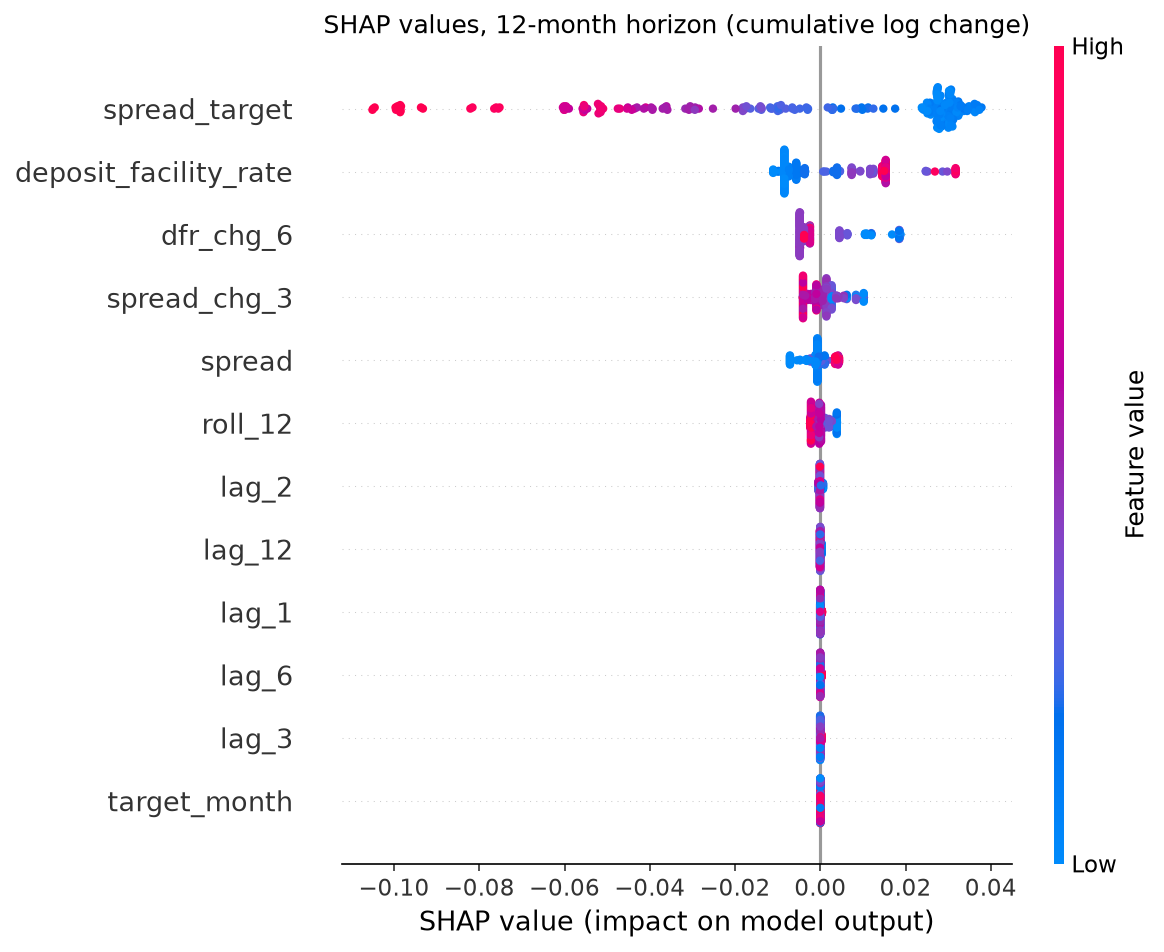

In [10]:
from deposit_forecasting.explain import mean_abs_shap
from deposit_forecasting.gbm import GradientBoostingForecaster

model = GradientBoostingForecaster().fit(panel)
shap_table = mean_abs_shap(model)
for h, part in shap_table.groupby("horizon"):
    print(f"Horizon {h}: top features by mean |SHAP|")
    display(part.head(5).set_index("feature")[["mean_abs_shap"]].round(4))
display(Image(DEFAULT_FIGURE_DIR / "shap_h12.png"))